## Introduction to Quantum Computing: Labs

### Lab 7: Grover Algorithm

The **Grover algorithm** is a key quantum algorithm for solving the problem of *unstructured search*.
It can find a target item among $N$ possibilities using only $O(\sqrt{N})$ oracle queries. Classical unstructured search, by contrast, requires $O(N)$ queries. Grover therefore provides a quadratic advantage in the number of queries. The total runtime also depends on the cost of implementing the oracle and the rest of the circuit.

The basic idea is to consider all possibilities simultaneously in a **superposition**, rather than checking each item individually.
By combining an **oracle** with **amplitude amplification**, the desired solutions are gradually amplified.

**Three building blocks:**

1. **Superposition:** Prepare a uniform superposition of all possible states.
2. **Oracle:** Mark the solution states by flipping the signs of their amplitudes.
3. **Amplitude amplification:** Amplify the marked states to increase their measurement probabilities.

After a few iterations, the probability of measuring the desired solution is very high.

In this lab, we will implement and analyze the Grover algorithm using a simple example.
We will search for the quantum state in which all qubits have the value 1.

We will treat **amplitude amplification** as a **black box** in this lab: We will use a provided circuit without discussing its derivation in detail.

In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qc_lecture_tools.statevector import sv_state

### Preparation

Throughout this notebook, we will use:

- `sv_state(quantum_circuit)` to examine the quantum state
- `quantum_circuit1.compose(quantum_circuit2, inplace=True)` to combine subcircuits
- `draw("mpl")` to draw circuits

Except in the bonus exercise, we will always search for exactly **one** target state: the state in which all qubits are 1, such as $\ket{111}$ for 3 qubits.


### Exercise 1: Uniform Superposition of 3 Data Qubits

First, we will put all three data qubits into a uniform superposition.
To do this, we apply a Hadamard gate to each data qubit.

Prepare a uniform superposition of 3 qubits and examine the state using `sv_state(quantum_circuit)`.


In [2]:
num_qubits = 3
qc_superposition = QuantumCircuit(num_qubits)

# TODO Exercise 1


### Exercise 2: A Simple Oracle for the State $\ket{111}$

We will now build an oracle that marks only the state $\ket{111}$. Here, marking means changing the sign of this state's amplitude to negative.

In principle, we can implement this using a multi-controlled $Z$ gate.

Unfortunately, a multi-controlled $Z$ gate is not directly available in Qiskit.
We will construct it from familiar building blocks: a multi-controlled $X$ gate and Hadamard gates. We use the relation $HXH = Z$ and proceed as follows:

- Use a multi-controlled $X$ gate (`mcx`).
- Apply Hadamard gates to the target qubit before and after the multi-controlled $X$ gate.
- This effectively produces a multi-controlled $Z$ gate.

**Exercise 2.1:** Build an oracle for 3 qubits that marks the state $\ket{111}$. You can test its behavior in Exercise 2.2.


In [3]:
num_qubits = 3
qc_oracle = QuantumCircuit(num_qubits)

# TODO Exercise 2.1


**Exercise 2.2:** Apply the oracle to the uniform superposition and examine the state using `sv_state`.
Use the `compose` function to combine the circuits. What do you observe? What does this mean for the measurement probabilities?

**Hint:** The following Qiskit function appends a second circuit (`quantum_circuit2`) to an existing circuit (`quantum_circuit1`):

```python
quantum_circuit1.compose(quantum_circuit2, inplace=True)
```

In [4]:
# TODO Exercise 2.2


### Exercise 3: Amplitude Amplification

Next, we will use amplitude amplification. In this lab, we will treat it as a **provided black box**.

We will use the function `amplitude_amplification`, which has already been implemented.
It creates the amplitude amplification circuit for a given number of qubits.

The key point here is that, after the oracle has been applied, amplitude amplification increases the amplitude of the marked state.

**Exercise 3.1:** Run the following cell and examine the circuit. Do you recognize any of its components?


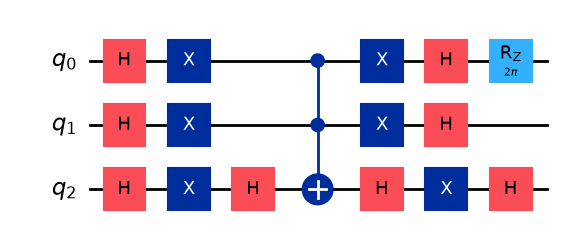

In [5]:
from qc_lecture_tools.grover import amplitude_amplification

num_qubits = 3
qc_amplification = amplitude_amplification(num_qubits, 0)
display(qc_amplification.draw("mpl"))

**Exercise 3.2:** Apply amplitude amplification to the state after the oracle and examine the result.


In [6]:
# TODO Exercise 3.2

### Exercise 4: Implementing the Grover Algorithm

The Grover algorithm starts by preparing a uniform superposition.

The oracle and amplitude amplification are then applied in several Grover steps.

One Grover step consists of:

1. The oracle
2. Amplitude amplification

The Grover algorithm usually requires several Grover steps. The oracle and amplitude amplification are therefore applied repeatedly, alternating between the two.

We will now investigate what happens to the probabilities when we perform several Grover steps.

**Exercise 4.1:** Apply the oracle and amplitude amplification a second time. What is the probability of measuring the correct state now?


In [7]:
# TODO Exercise 4.1

**Exercise 4.2:** Perform a third Grover step. Compare the output with the previous cells. What has happened now?


In [8]:
# TODO Exercise 4.2

### Exercise 5: What Happens with 4 or 5 Qubits?

As the number of qubits increases, so does the total number of basis states:

- 4 qubits: $2^4 = 16$
- 5 qubits: $2^5 = 32$

However, we are still searching for only **one** state, in this case $\ket{1\ldots1}$.
This is why we need **more Grover steps** when we use more qubits.

Since our quantum state now contains many basis states, we will use a more compact output format.

Use the function `print_grover_states(quantum_circuit, num_qubits)` for this.


**Exercise 5.1:** Implement the Grover algorithm for 4 qubits.
Use the code from the previous exercises and adapt the circuits to the new number of qubits.
How many Grover steps are needed to maximize the probability of measuring the state $\ket{1111}$?


In [9]:
from qc_lecture_tools.grover import print_grover_states

num_qubits = 4

qc_superposition_4 = QuantumCircuit(num_qubits)
# TODO Exercise 5.1: Prepare the superposition

qc_oracle_4 = QuantumCircuit(num_qubits)
# TODO Exercise 5.1: Implement the oracle

qc_amplitude_amplification_4 = amplitude_amplification(num_qubits, 0)

qc_grover_4 = QuantumCircuit(num_qubits)
# TODO Exercise 5.1: Combine the subcircuits and investigate the Grover steps

print_grover_states(qc_grover_4, num_qubits)


Found basis states with non-zero amplitudes:
0000:  1.00  Probability:  1.00


**Exercise 5.2:** Repeat the example for **5 data qubits** and the target state $\ket{11111}$.


In [10]:
num_qubits = 5

qc_superposition_5 = QuantumCircuit(num_qubits)
# TODO Exercise 5.2: Prepare the superposition

qc_oracle_5 = QuantumCircuit(num_qubits)
# TODO Exercise 5.2: Implement the oracle

qc_amplification_5 = amplitude_amplification(num_qubits, 0)

qc_grover_5 = QuantumCircuit(num_qubits)
# TODO Exercise 5.2: Combine the subcircuits and investigate the Grover steps

print_grover_states(qc_grover_5, num_qubits)


Found basis states with non-zero amplitudes:
00000:  1.00  Probability:  1.00


### Exercise 6: Compute–Uncompute and Ancilla Qubits

So far, we have constructed the oracle using our knowledge of the target state, $\ket{1\ldots1}$.
We will now implement an oracle using a logical query, without specifying the solution directly.

As in Lab 6 (Logical Queries), we need additional qubits, called **ancilla qubits**, to store intermediate results of the logical query.

We distinguish between:

- **Data qubits:** The qubits whose states we want to search using the Grover algorithm.
- **Ancilla qubits:** Additional qubits needed to implement the oracle.

We can store the result of the logical query in an additional ancilla qubit and then apply a $Z$ gate to it.

After computing the logical query, the ancilla qubits are generally entangled with the data qubits.
For the subsequent amplitude amplification on the data qubits to work as intended, the ancilla qubits must be returned to their initial state **before this step**. The phase marking produced by the $Z$ gate remains on the data qubits.

This is done in the **uncompute** step. Afterwards, the ancilla qubits are disentangled from the data qubits and can be reused in subsequent oracle calls.

The idea behind the compute–uncompute oracle is:

1. **Compute** the condition "all data qubits are 1" into the ancilla qubit.
2. Apply a $Z$ gate to the ancilla qubit.
3. **Undo** the computation.

At the end, the ancilla qubit is back in its initial state.

Keep in mind throughout this notebook:
The **superposition is prepared only on the data qubits**. The ancilla qubit starts in the state $\ket{0}$.


**Exercise 6.1:** Start with a uniform superposition again. Here, apply Hadamard gates only to the data qubits, leaving the ancilla qubit unchanged.


In [11]:
num_qubits = 3
num_ancilla_qubits = 1
num_qubits = num_qubits + num_ancilla_qubits

qc_superposition = QuantumCircuit(num_qubits)

# TODO Exercise 6.1


**Exercise 6.2:** We will now build a compute–uncompute implementation of an oracle that finds the state $\ket{111}$.
Use the multi-controlled $X$ gate `mcx` to change the ancilla qubit from 0 to 1 when all three data qubits have the value 1.
Then apply a $Z$ gate to the ancilla qubit. In the final step, the ancilla qubit must be returned to 0. How can you do this?

Implement the compute–uncompute version of the oracle.

Test your implementation by applying the oracle to the uniform superposition and analyzing the state.
The amplitude of the data state $\ket{111}$ should be negative, and the additional fourth qubit (the ancilla qubit) should be back at 0.


In [12]:
num_qubits = 3
num_ancilla_qubits = 1
num_qubits = num_qubits + num_ancilla_qubits

qc_oracle_compute_uncompute = QuantumCircuit(num_qubits)
# TODO Exercise 6.2: Implement the compute–uncompute oracle

qc_after_oracle_compute_uncompute = QuantumCircuit(num_qubits)
# TODO Exercise 6.2: Apply the oracle to the uniform superposition and examine the state


**Exercise 6.3:** A Complete Grover Step with a Compute–Uncompute Oracle

Implement the Grover algorithm again. Use the provided amplitude amplification function:

> `amplitude_amplification(3, 1)`

The first argument is the number of data qubits, and the second is the number of ancilla qubits.

Analyze the state after one and after two Grover steps.


In [13]:
qc_grover = QuantumCircuit(num_qubits)

# TODO Exercise 6.3


### Bonus Exercise: A New Oracle

**Exercise 7.1:**
We will now change the target states. We want to find all states in which **exactly two** qubits have the value 1.
This can be implemented using three doubly controlled and one triply controlled $X$ gate.
The query should work on 3 data qubits.

Implement the corresponding compute–uncompute oracle.

Test your circuit as before by applying it to the uniform superposition.


In [14]:
qc_compute_uncompute_7 = QuantumCircuit(num_qubits)

# TODO Exercise 7.1: Implement the compute–uncompute oracle


In [15]:
qc_grover = QuantumCircuit(num_qubits)

# TODO Exercise 7.1: Apply the oracle to the uniform superposition and examine the state


**Exercise 7.2:** Implement the Grover algorithm again. What are the probabilities in this case?
Analyze the circuit's result after one Grover step using `print_grover_states(quantum_circuit, 3)`.


In [16]:
qc_grover = QuantumCircuit(num_qubits)

# TODO Exercise 7.2
